# Vuelos de Lévy en el modelo de hormigas forrajeras

En el modelo **Ants** de la biblioteca de NetLogo (Wilensky, 1997), una colonia de hormigas sale del nido, busca comida moviéndose al azar, y al encontrarla regresa al nido dejando un rastro de feromona que guía a las demás. Aquí cambiamos la estrategia de búsqueda por **vuelos de Lévy** y medimos si las hormigas encuentran la comida más rápido.

**Cómo está organizado este trabajo.**

* **Python (este notebook).** Reimplementamos el modelo de NetLogo en Python, siguiendo su código línea por línea, para poder correr cientos de simulaciones y hacer estadística en el mismo lugar donde se explica todo.
* **NetLogo (archivo aparte).** El enunciado pide añadir el código en un archivo separado: el modelo de NetLogo modificado está en [`Ants-Levy.nlogo`](https://github.com/uncrayon/biologia-matematica/blob/main/assets/netlogo/Ants-Levy.nlogo). Agrega un selector de movimiento (caminata aleatoria o vuelos de Lévy), los deslizadores `mu` y `paso-maximo`, tres escenarios de comida y un experimento de BehaviorSpace para repetir las simulaciones. Lo ejecutamos en NetLogo 6.4.0 y sus resultados coinciden con los de la versión en Python (sección 6).

**Contenido**

1. El modelo de hormigas y su reimplementación.
2. Sin comida ni feromona: ¿es una caminata aleatoria?
3. Vuelos de Lévy: la distribución de pasos y sus beneficios.
4. Hormigas con vuelos de Lévy.
5. Eficiencia: muchas simulaciones, media y desviación estándar.
6. Verificación con NetLogo.
7. ¿En qué condiciones ganan los vuelos de Lévy?

## 1. El modelo de hormigas

Las reglas del modelo original, en cada paso de tiempo (*tick*), para cada hormiga:

* **Si no lleva comida:** si está sobre comida, la toma, da media vuelta y empieza a regresar. Si no, y huele feromona en una concentración intermedia ($0.05 \le c < 2$), "olfatea" adelante, a 45° a la derecha y a 45° a la izquierda, y gira hacia donde el olor es más fuerte.
* **Si lleva comida:** si está en el nido, la deja y da media vuelta. Si no, deja 60 unidades de feromona en su parcela y gira hacia donde el "olor a nido" (que es mayor cerca del nido) es más fuerte.
* **Siempre:** se "menea" (*wiggle*): gira a la derecha un ángulo entero al azar entre 0 y 39 grados y luego a la izquierda otro ángulo igual de aleatorio. Si el paso la sacaría del mundo, da media vuelta. Después avanza una parcela.
* **La feromona** se difunde a las 8 parcelas vecinas (50 % por tick) y se evapora (10 % por tick).

El mundo mide 71 × 71 parcelas sin bordes periódicos; el nido está en el centro, hay 125 hormigas que salen una por tick y tres fuentes de comida.

La celda siguiente contiene la reimplementación. Los únicos cambios respecto al original son:

1. El parámetro `movimiento="levy"`: mientras una hormiga **busca comida y no huele feromona**, en vez de menearse sigue un vuelo de Lévy (sección 4). En cuanto huele feromona, encuentra comida o choca con una pared, abandona el vuelo y se comporta como en el original. Así el reclutamiento por feromona no cambia: solo cambia la **búsqueda**.
2. Varios **escenarios** de comida: `original` (las tres fuentes de NetLogo), `lejana` (una sola fuente pequeña en una esquina), `dispersa` (12 fuentes diminutas en lugares al azar) y `sin-comida`.
3. El tamaño del mundo (`max_p`) es un parámetro.

Una pequeña diferencia técnica: en NetLogo las hormigas actúan una tras otra, de modo que la feromona que deja una puede ser olida por la siguiente en el mismo tick. Aquí todas deciden con el estado al inicio del tick (salvo al recoger comida, que se resuelve en orden aleatorio para que dos hormigas no se lleven la misma unidad). No cambia el comportamiento colectivo.

In [1]:
# ============================================================
# Modelo de hormigas forrajeras (reimplementación del modelo
# "Ants" de NetLogo) con la opción de vuelos de Lévy
# ============================================================
import numpy as np



class Hormiguero:
    """
    Reimplementación en Python del modelo "Ants" de NetLogo (Wilensky, 1997),
    con la opción de que las hormigas busquen comida con vuelos de Lévy.

    Parámetros
    ----------
    movimiento : "caminata" (modelo original) o "levy".
    mu : exponente de la ley de potencias P(l) ~ l^(-mu) (solo para "levy").
    paso_maximo : longitud máxima de un vuelo (el mundo mide 71 parcelas).
    escenario : "original", "lejana", "dispersa" o "sin-comida".
    poblacion, difusion, evaporacion : como los deslizadores de NetLogo.
    rng : generador de números aleatorios de numpy.
    """

    def __init__(self, movimiento="caminata", mu=2.0, paso_maximo=100, escenario="original",
                 poblacion=125, difusion=50, evaporacion=10, max_p=35, rng=None):
        self.rng = rng if rng is not None else np.random.default_rng()
        self.movimiento, self.mu, self.paso_maximo = movimiento, mu, paso_maximo
        self.difusion, self.evaporacion = difusion / 100, evaporacion / 100
        self.max_p = max_p                 # el mundo va de -max_p a max_p en x y en y
        self.lado = 2 * max_p + 1          # número de parcelas por lado

        # --- Parcelas (patches). Índice [i, j] <-> coordenadas (i - 35, j - 35).
        c = np.arange(-self.max_p, self.max_p + 1)
        self.PX, self.PY = np.meshgrid(c, c, indexing="ij")
        dist_nido = np.hypot(self.PX, self.PY)
        self.nido = dist_nido < 5                    # nest?
        self.olor_nido = 200 - dist_nido             # nest-scent
        self.quimico = np.zeros((self.lado, self.lado))        # chemical
        self.comida = np.zeros((self.lado, self.lado), int)    # food
        self._poner_comida(escenario)
        self.comida_inicial = self.comida.sum()

        # --- Hormigas: todas empiezan en el nido con dirección aleatoria.
        n = poblacion
        self.x = np.zeros(n)
        self.y = np.zeros(n)
        self.rumbo = self.rng.integers(0, 360, n).astype(float)   # 0 = norte, sentido horario
        self.cargando = np.zeros(n, bool)
        self.pasos_restantes = np.zeros(n, int)      # pasos que le quedan al vuelo de Lévy actual
        self.ticks = 0
        self.recolectada = 0                         # unidades de comida llevadas al nido
        self.primer_hallazgo = None                  # tick en que se encontró comida por primera vez

    # ------------------------------------------------------------------
    def _poner_comida(self, escenario):
        """Coloca la comida según el escenario (1 o 2 unidades por parcela, al azar)."""
        fuente = np.zeros((self.lado, self.lado), bool)
        disco = lambda cx, cy, r: np.hypot(self.PX - cx, self.PY - cy) < r
        if escenario == "original":       # las tres fuentes del modelo de NetLogo
            fuente |= disco(0.6 * self.max_p, 0, 5)
            fuente |= disco(-0.6 * self.max_p, -0.6 * self.max_p, 5)
            fuente |= disco(-0.8 * self.max_p, 0.8 * self.max_p, 5)
        elif escenario == "lejana":       # una sola fuente pequeña en una esquina
            fuente |= disco(0.8 * self.max_p, -0.8 * self.max_p, 3)
        elif escenario == "dispersa":     # 12 fuentes diminutas en lugares al azar
            candidatos = np.argwhere(np.hypot(self.PX, self.PY) > 10)
            for k in self.rng.choice(len(candidatos), 12, replace=False):
                i, j = candidatos[k]
                fuente |= np.hypot(self.PX - self.PX[i, j], self.PY - self.PY[i, j]) <= 1.5
        elif escenario != "sin-comida":
            raise ValueError(f"escenario desconocido: {escenario}")
        self.comida[fuente] = self.rng.integers(1, 3, fuente.sum())

    def _parcela(self, x, y):
        """Índices de la parcela que contiene el punto (x, y) y si está dentro del mundo."""
        i = np.floor(x + 0.5).astype(int) + self.max_p
        j = np.floor(y + 0.5).astype(int) + self.max_p
        dentro = (i >= 0) & (i < self.lado) & (j >= 0) & (j < self.lado)
        return i, j, dentro

    def _valor_en_angulo(self, campo, x, y, rumbo, angulo):
        """Como chemical-scent-at-angle de NetLogo: valor de `campo` 1 paso adelante
        girando `angulo` grados; 0 si esa parcela está fuera del mundo."""
        h = np.deg2rad(rumbo + angulo)
        i, j, dentro = self._parcela(x + np.sin(h), y + np.cos(h))
        valor = np.zeros(len(x))
        valor[dentro] = campo[i[dentro], j[dentro]]
        return valor

    def _subir_gradiente(self, campo, idx):
        """uphill-chemical / uphill-nest-scent para las hormigas `idx`."""
        if len(idx) == 0:
            return
        x, y, r = self.x[idx], self.y[idx], self.rumbo[idx]
        adelante = self._valor_en_angulo(campo, x, y, r, 0)
        derecha = self._valor_en_angulo(campo, x, y, r, 45)
        izquierda = self._valor_en_angulo(campo, x, y, r, -45)
        gira = (derecha > adelante) | (izquierda > adelante)
        self.rumbo[idx] += np.where(gira, np.where(derecha > izquierda, 45, -45), 0)

    # ------------------------------------------------------------------
    def paso(self):
        """Un tick del modelo (procedimiento `go` de NetLogo)."""
        rng = self.rng
        n = len(self.x)
        # Salida escalonada: la hormiga número `who` empieza a moverse en el tick who + 1.
        activa = np.arange(n) < self.ticks
        i, j, _ = self._parcela(self.x, self.y)

        # --- 1) Hormigas que buscan comida (look-for-food).
        buscando = activa & ~self.cargando
        recien_cargo = np.zeros(n, bool)
        sobre_comida = np.flatnonzero(buscando & (self.comida[i, j] > 0))
        for a in rng.permutation(sobre_comida):            # en orden aleatorio, como NetLogo
            if self.comida[i[a], j[a]] > 0:                # puede que otra ya se la llevó
                self.comida[i[a], j[a]] -= 1
                self.cargando[a] = recien_cargo[a] = True
                self.rumbo[a] += 180
                if self.primer_hallazgo is None:
                    self.primer_hallazgo = self.ticks
        q = self.quimico[i, j]
        sigue_rastro = buscando & ~recien_cargo & (q >= 0.05) & (q < 2)
        self._subir_gradiente(self.quimico, np.flatnonzero(sigue_rastro))

        # --- 2) Hormigas que regresan con comida (return-to-nest).
        regresando = activa & self.cargando & ~recien_cargo
        en_nido = regresando & self.nido[i, j]
        self.cargando[en_nido] = False
        self.rumbo[en_nido] += 180
        self.recolectada += en_nido.sum()
        fuera = np.flatnonzero(regresando & ~en_nido)
        np.add.at(self.quimico, (i[fuera], j[fuera]), 60)   # deja feromona
        self._subir_gradiente(self.olor_nido, fuera)

        # --- 3) Movimiento: vuelo de Lévy (solo si busca y no huele feromona) o "wiggle".
        if self.movimiento == "levy":
            q = self.quimico[i, j]
            levy = activa & ~self.cargando & (q < 0.05)
        else:
            levy = np.zeros(n, bool)
        nuevo_vuelo = levy & (self.pasos_restantes <= 0)
        k = nuevo_vuelo.sum()
        if k:
            self.rumbo[nuevo_vuelo] = rng.uniform(0, 360, k)
            self.pasos_restantes[nuevo_vuelo] = longitudes_levy(self.mu, k, self.paso_maximo, rng)
        self.pasos_restantes[levy] -= 1
        self.pasos_restantes[~levy] = 0           # quien deja de buscar abandona su vuelo
        wiggle = activa & ~levy
        self.rumbo[wiggle] += rng.integers(0, 40, wiggle.sum()) - rng.integers(0, 40, wiggle.sum())

        # can-move? 1: si el paso saldría del mundo, media vuelta.
        h = np.deg2rad(self.rumbo)
        _, _, puede = self._parcela(self.x + np.sin(h), self.y + np.cos(h))
        rebota = activa & ~puede
        self.rumbo[rebota] += 180
        self.pasos_restantes[rebota] = 0          # un vuelo que choca con la pared termina
        self.rumbo %= 360

        # fd 1
        h = np.deg2rad(self.rumbo[activa])
        self.x[activa] = np.clip(self.x[activa] + np.sin(h), -self.max_p - 0.49, self.max_p + 0.49)
        self.y[activa] = np.clip(self.y[activa] + np.cos(h), -self.max_p - 0.49, self.max_p + 0.49)

        # --- 4) La feromona se difunde y se evapora (si no hay feromona en
        # ningún lado nos ahorramos la cuenta: el resultado sería cero).
        if self.quimico.any():
            self._difundir()
            self.quimico *= 1 - self.evaporacion
        self.ticks += 1

    def _difundir(self):
        """`diffuse chemical rate` en un mundo sin bordes periódicos: cada parcela reparte
        rate * chemical / 8 a cada vecina; la parte de las vecinas inexistentes se queda."""
        parte = self.difusion * self.quimico / 8
        p = np.pad(parte, 1)
        recibido = sum(np.roll(np.roll(p, di, 0), dj, 1)[1:-1, 1:-1]
                       for di in (-1, 0, 1) for dj in (-1, 0, 1) if (di, dj) != (0, 0))
        vecinos = np.full((self.lado, self.lado), 8)
        vecinos[[0, -1], :] = 5
        vecinos[:, [0, -1]] = 5
        vecinos[[0, 0, -1, -1], [0, -1, 0, -1]] = 3
        self.quimico = self.quimico * (1 - self.difusion) + recibido + parte * (8 - vecinos)


def longitudes_levy(mu, k, paso_maximo, rng):
    """
    k longitudes de vuelo con P(l) ~ l^(-mu) para l >= 1 (distribución de Pareto),
    por transformada inversa: si U ~ Uniforme(0, 1], l = U^(-1/(mu - 1)).
    Se truncan en `paso_maximo` y se redondean hacia arriba a pasos enteros.
    """
    u = 1 - rng.random(k)                     # en (0, 1]
    l = u ** (-1 / (mu - 1))
    return np.ceil(np.minimum(l, paso_maximo)).astype(int)

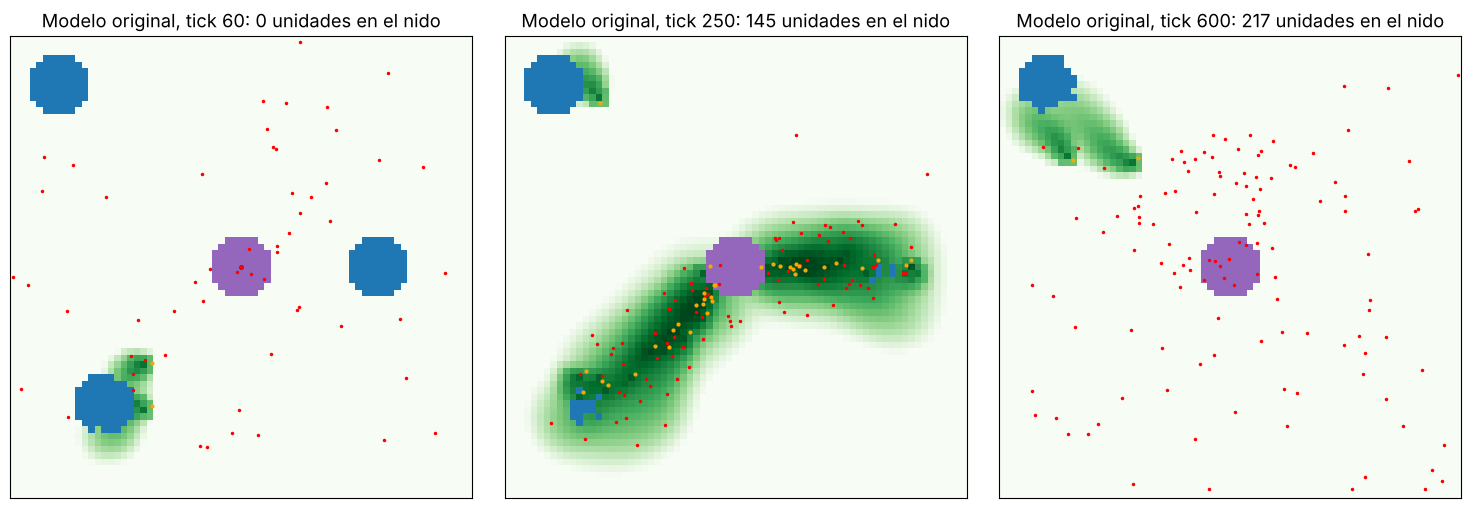

In [2]:
# ============================================================
# Herramientas generales del análisis
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import stats

plt.rcParams.update({"figure.dpi": 100, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(1997)   # semilla fija: resultados reproducibles


def dibujar_mundo(ax, h, titulo):
    """Dibuja feromona (verde), comida (azul), nido (violeta) y hormigas (rojo: buscan; naranja: cargan)."""
    m = h.max_p
    extent = (-m - 0.5, m + 0.5, -m - 0.5, m + 0.5)
    ax.imshow(np.log10(h.quimico.T + 1e-2), origin="lower", extent=extent, cmap="Greens", vmin=-1, vmax=2)
    capa = np.where(h.comida.T > 0, 1.0, np.where(h.nido.T, 2.0, np.nan))
    ax.imshow(capa, origin="lower", extent=extent, cmap=ListedColormap(["tab:blue", "tab:purple"]),
              vmin=1, vmax=2, interpolation="nearest")
    ax.plot(h.x[~h.cargando], h.y[~h.cargando], ".", color="red", ms=3)
    ax.plot(h.x[h.cargando], h.y[h.cargando], ".", color="orange", ms=4)
    ax.set_title(titulo)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)


# Una corrida del modelo original para verlo funcionar.
h = Hormiguero(rng=rng)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, t_obj in zip(axs, [60, 250, 600]):
    while h.ticks < t_obj:
        h.paso()
    dibujar_mundo(ax, h, f"Modelo original, tick {h.ticks}: {h.recolectada} unidades en el nido")
plt.tight_layout()
plt.show()

## 2. Sin comida ni feromona: ¿una caminata aleatoria?

Usamos el escenario `sin-comida`. Como ninguna hormiga encuentra comida, ninguna deja feromona y lo único que queda es el meneo: girar $U_1 - U_2$ grados, con $U_1, U_2$ enteros uniformes entre 0 y 39, y avanzar una parcela. Registramos las trayectorias y medimos:

* **Longitud de paso:** la distancia recorrida en cada tick.
* **Ángulo de giro:** el cambio de dirección entre ticks consecutivos (excluyendo los rebotes en las paredes, que son giros de 180°).

**Predicción teórica.** La diferencia de dos uniformes discretas tiene una distribución **triangular** entre −39° y 39°, con media 0. Una caminata cuyos pasos tienen longitud fija y cuyos giros son independientes, pero pequeños, es una **caminata aleatoria correlacionada**: la hormiga tiende a seguir en la misma dirección por un rato. Si $\bar c = E[\cos\theta]$ es el coseno medio del giro, el desplazamiento cuadrático medio después de $n$ pasos de longitud 1 es

$$
\langle R_n^2\rangle = n\,\frac{1 + \bar c}{1 - \bar c} - \frac{2\bar c\,(1 - \bar c^{\,n})}{(1 - \bar c)^2}.
$$

Para $n$ pequeño $\langle R_n^2 \rangle \approx n^2$ (movimiento casi recto, **balístico**) y para $n$ grande $\langle R_n^2\rangle \approx n(1+\bar c)/(1-\bar c)$ (crece linealmente, **difusivo**, como el movimiento browniano).

In [3]:
T_RW = 400
h = Hormiguero(escenario="sin-comida", rng=rng)
n_h = len(h.x)
pos = np.full((T_RW + 1, n_h, 2), np.nan)     # posiciones de cada hormiga en cada tick
rumbos = np.full((T_RW + 1, n_h), np.nan)
for t in range(T_RW + 1):
    pos[t, :, 0], pos[t, :, 1] = h.x, h.y
    rumbos[t] = h.rumbo
    h.paso()

# Solo usamos ticks en los que la hormiga ya había salido (who < tick).
activa = np.arange(n_h)[None, :] < np.arange(T_RW + 1)[:, None]
desplazamiento = np.diff(pos, axis=0)
longitudes = np.hypot(desplazamiento[..., 0], desplazamiento[..., 1])[activa[1:] & activa[:-1]]
giros = (np.diff(rumbos, axis=0) + 180) % 360 - 180          # en [-180, 180)
giros = giros[activa[1:] & activa[:-1]]
rebotes = np.abs(giros) > 90                                   # media vuelta en una pared
giros_libres = giros[~rebotes]

print(f"Longitud de paso: media = {longitudes.mean():.4f}, desv. est. = {longitudes.std():.4f}")
print(f"Fracción de pasos con rebote en una pared: {rebotes.mean():.3f}")
print(f"Ángulo de giro (sin rebotes): media = {giros_libres.mean():+.2f}°, desv. est. = {giros_libres.std():.2f}°")

# Distribución teórica del giro: diferencia de dos uniformes en {0, ..., 39}.
valores = np.arange(-39, 40)
p_teo = (40 - np.abs(valores)) / 40**2
c_bar = np.sum(p_teo * np.cos(np.deg2rad(valores)))
print(f"Teoría: desv. est. = {np.sqrt(np.sum(p_teo * valores**2)):.2f}°, E[cos θ] = {c_bar:.4f}")
print(f"Longitud de persistencia ≈ (1 + c)/(1 - c) = {(1 + c_bar) / (1 - c_bar):.1f} pasos")

Longitud de paso: media = 1.0000, desv. est. = 0.0011
Fracción de pasos con rebote en una pared: 0.016
Ángulo de giro (sin rebotes): media = -0.10°, desv. est. = 16.31°
Teoría: desv. est. = 16.32°, E[cos θ] = 0.9601
Longitud de persistencia ≈ (1 + c)/(1 - c) = 49.1 pasos


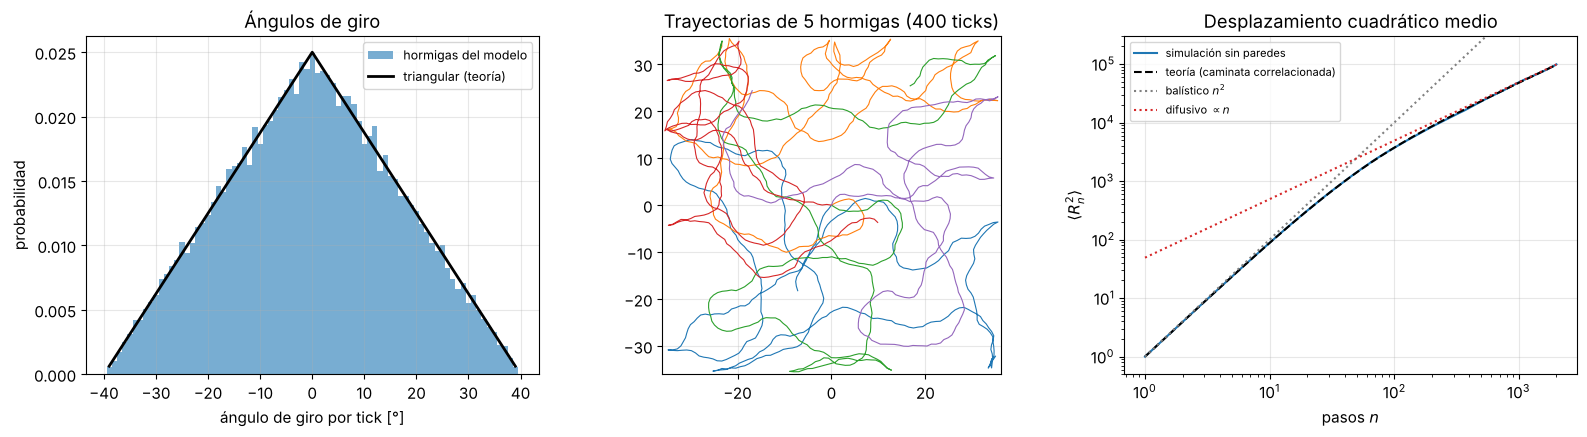

In [4]:
def msd_teorico(n, c):
    """Desplazamiento cuadrático medio de una caminata correlacionada con pasos de longitud 1."""
    return n * (1 + c) / (1 - c) - 2 * c * (1 - c**n) / (1 - c) ** 2


def caminata_libre(n_pasos, n_caminantes, rng):
    """La misma regla de meneo pero en un plano sin paredes: regresa las posiciones."""
    giros = rng.integers(0, 40, (n_pasos, n_caminantes)) - rng.integers(0, 40, (n_pasos, n_caminantes))
    rumbo = np.deg2rad(rng.uniform(0, 360, n_caminantes) + np.cumsum(giros, axis=0))
    x = np.vstack([np.zeros(n_caminantes), np.cumsum(np.sin(rumbo), axis=0)])
    y = np.vstack([np.zeros(n_caminantes), np.cumsum(np.cos(rumbo), axis=0)])
    return x, y


fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
# (a) histograma de los ángulos de giro contra la distribución triangular
axs[0].hist(giros_libres, bins=np.arange(-39.5, 40.5, 1), density=True, alpha=0.6, label="hormigas del modelo")
axs[0].plot(valores, p_teo, "k", lw=2, label="triangular (teoría)")
axs[0].set_xlabel("ángulo de giro por tick [°]")
axs[0].set_ylabel("probabilidad")
axs[0].set_title("Ángulos de giro")
axs[0].legend(fontsize=9)

# (b) algunas trayectorias en el mundo del modelo
for a in range(0, 125, 25):
    axs[1].plot(pos[:, a, 0], pos[:, a, 1], lw=0.8)
axs[1].set_xlim(-36, 36)
axs[1].set_ylim(-36, 36)
axs[1].set_aspect("equal")
axs[1].set_title(f"Trayectorias de 5 hormigas ({T_RW} ticks)")

# (c) desplazamiento cuadrático medio: plano libre contra teoría
n = np.arange(1, 2001)
xl, yl = caminata_libre(2000, 2000, rng)
msd_libre = (xl[1:] ** 2 + yl[1:] ** 2).mean(axis=1)
axs[2].loglog(n, msd_libre, label="simulación sin paredes")
axs[2].loglog(n, msd_teorico(n, c_bar), "k--", label="teoría (caminata correlacionada)")
axs[2].loglog(n, n.astype(float) ** 2, ":", color="gray", label="balístico $n^2$")
axs[2].loglog(n, n * (1 + c_bar) / (1 - c_bar), ":", color="C3", label="difusivo $\\propto n$")
axs[2].set_ylim(0.5, 3e5)
axs[2].set_xlabel("pasos $n$")
axs[2].set_ylabel(r"$\langle R_n^2\rangle$")
axs[2].set_title("Desplazamiento cuadrático medio")
axs[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Conclusión de la parte 1.** Sin comida ni feromona, las hormigas hacen una **caminata aleatoria correlacionada**:

* Todos los pasos miden exactamente 1 (salvo en las paredes): la longitud de paso no es aleatoria.
* Los ángulos de giro siguen la distribución triangular predicha, centrada en 0 y sin preferencia por izquierda o derecha.
* Como los giros son pequeños (desviación estándar de unos 16°, $\bar c \approx 0.96$), la hormiga mantiene su dirección durante muchos pasos: es **persistente**, con una longitud de persistencia de unos 50 pasos, del orden del tamaño del mundo (71 parcelas). A escalas mucho más largas su desplazamiento crece como $\sqrt n$, igual que una caminata aleatoria simple o el movimiento browniano. La curva simulada coincide con la fórmula teórica.
* En los bordes del mundo el comportamiento cambia: las hormigas rebotan y su desplazamiento se satura en el tamaño del mundo. "Mirar los límites", como pide el enunciado, muestra que las paredes atrapan y concentran trayectorias en los bordes.

Este detalle será decisivo en lo que sigue: la búsqueda original **no es** una caminata browniana sin memoria. En la escala del hormiguero se mueve casi en línea recta y no regresa constantemente sobre sus pasos.

## 3. Vuelos de Lévy

### Descripción matemática

En un vuelo de Lévy, la hormiga elige una dirección uniforme al azar y avanza en línea recta una distancia $l$ tomada de una ley de potencias,

$$
P(l) = (\mu - 1)\,l^{-\mu}, \qquad l \ge 1,\quad 1 < \mu \le 3 .
$$

(El factor $\mu - 1$ normaliza la distribución; para $\mu \le 1$ no se puede normalizar.) Para muestrear usamos la **transformada inversa**: si $U$ es uniforme en $(0, 1]$, entonces $l = U^{-1/(\mu-1)}$ tiene esa distribución, porque $P(L > l) = l^{-(\mu-1)}$.

Propiedades clave según $\mu$:

* $1 < \mu \le 2$: la **media** de $l$ es infinita. Los pasos largos dominan el desplazamiento; con $\mu \to 1$ el movimiento es prácticamente en línea recta (**balístico**).
* $2 < \mu \le 3$: la media es finita pero la **varianza** infinita: sigue habiendo pasos larguísimos ocasionales.
* $\mu > 3$: media y varianza finitas; por el teorema central del límite el movimiento a largas escalas es **browniano**.

Al **crecer** $\mu$, los pasos largos se vuelven rarísimos y la caminata se parece cada vez más a una caminata aleatoria ordinaria. Al **decrecer** $\mu$, el movimiento se vuelve dominado por trayectos largos y rectos.

**¿Y una caminata por CU?** Piensa en un día en Ciudad Universitaria: casi todos tus desplazamientos son cortos (de un salón a otro, al baño, a la cafetería de la facultad) y de vez en cuando haces uno muy largo (a la Biblioteca Central, al Metro, a otra facultad). Eso es justamente una distribución de pasos con cola pesada. Con $\mu$ cercano a 1, casi todo tu día serían trayectos largos de un extremo al otro del campus; con $\mu$ cercano a 3 o más, casi no saldrías de tu edificio.

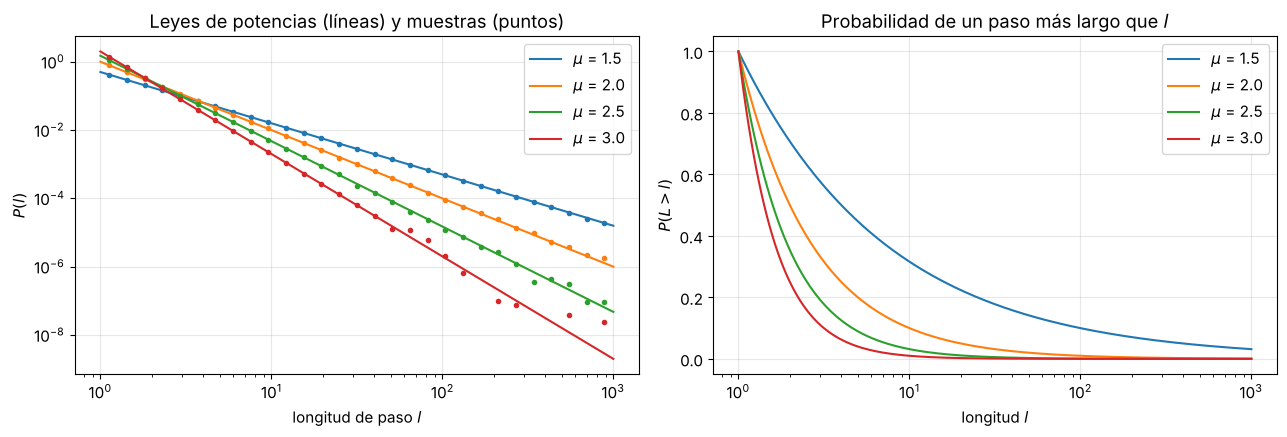

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
l = np.logspace(0, 3, 200)
for mu in [1.5, 2.0, 2.5, 3.0]:
    axs[0].loglog(l, (mu - 1) * l ** (-mu), label=rf"$\mu$ = {mu}")
    # Verificamos el muestreador: histograma con contenedores logarítmicos
    # (sin truncar, para comparar con la densidad exacta).
    muestra = (1 - rng.random(200_000)) ** (-1 / (mu - 1))
    bordes = np.logspace(0, 3, 30)
    cuentas, _ = np.histogram(muestra, bins=bordes)
    centros = np.sqrt(bordes[1:] * bordes[:-1])
    axs[0].loglog(centros, cuentas / (len(muestra) * np.diff(bordes)), "o", ms=3, color=axs[0].lines[-1].get_color())
axs[0].set_xlabel("longitud de paso $l$")
axs[0].set_ylabel("$P(l)$")
axs[0].set_title("Leyes de potencias (líneas) y muestras (puntos)")
axs[0].legend()

for mu in [1.5, 2.0, 2.5, 3.0]:
    axs[1].semilogx(l, l ** (-(mu - 1)), label=rf"$\mu$ = {mu}")
axs[1].set_xlabel("longitud $l$")
axs[1].set_ylabel(r"$P(L > l)$")
axs[1].set_title("Probabilidad de un paso más largo que $l$")
axs[1].legend()
plt.tight_layout()
plt.show()

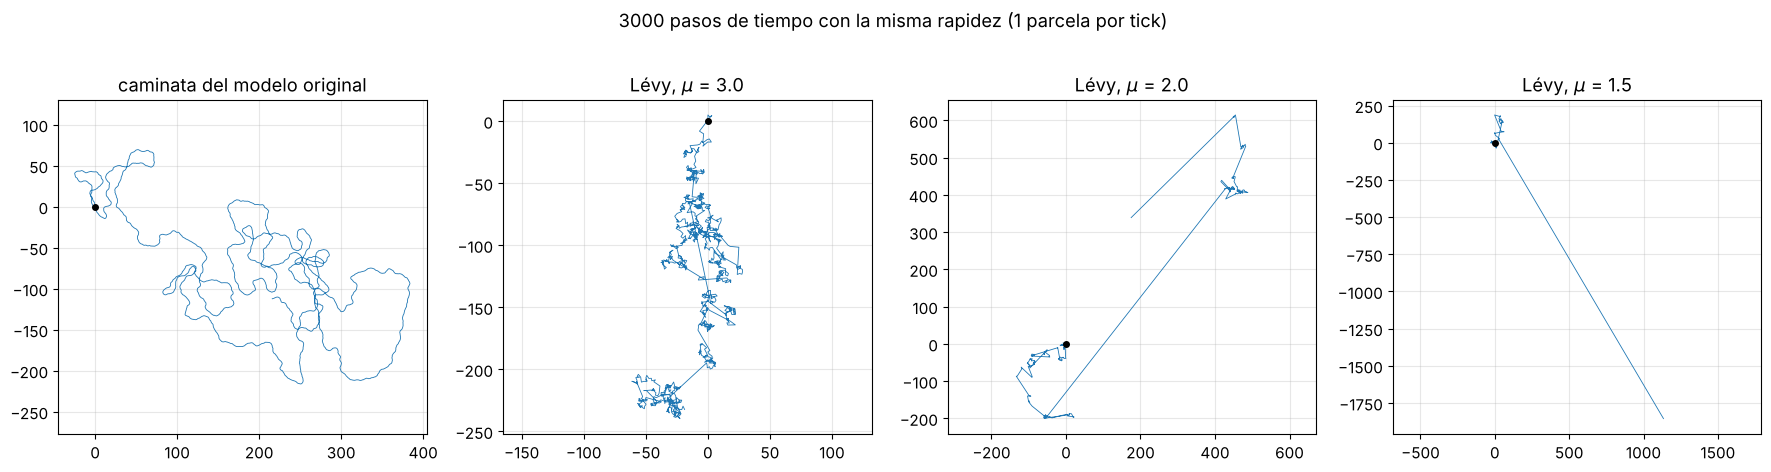

In [6]:
def caminata_levy_libre(mu, n_pasos, rng, paso_maximo=10_000):
    """
    Trayectoria de una caminata de Lévy en el plano libre, avanzando una unidad por
    paso de tiempo (como las hormigas): elige dirección uniforme y longitud
    l ~ l^(-mu), recorre l unidades en línea recta y repite.
    """
    x, y = [0.0], [0.0]
    while len(x) <= n_pasos:
        ang = rng.uniform(0, 2 * np.pi)
        largo = longitudes_levy(mu, 1, paso_maximo, rng)[0]
        for _ in range(min(largo, n_pasos + 1 - len(x))):
            x.append(x[-1] + np.sin(ang))
            y.append(y[-1] + np.cos(ang))
    return np.array(x), np.array(y)


fig, axs = plt.subplots(1, 4, figsize=(18, 4.6))
xl, yl = caminata_libre(3000, 1, rng)
axs[0].plot(xl[:, 0], yl[:, 0], lw=0.6)
axs[0].set_title("caminata del modelo original")
for ax, mu in zip(axs[1:], [3.0, 2.0, 1.5]):
    x, y = caminata_levy_libre(mu, 3000, rng)
    ax.plot(x, y, lw=0.6)
    ax.set_title(rf"Lévy, $\mu$ = {mu}")
for ax in axs:
    ax.set_aspect("equal", adjustable="datalim")
    ax.plot(0, 0, "ko", ms=4)
plt.suptitle("3000 pasos de tiempo con la misma rapidez (1 parcela por tick)", y=1.02)
plt.tight_layout()
plt.show()

### Beneficios de los vuelos de Lévy

La idea clásica (Viswanathan et al., 1999) es la siguiente. Si los recursos son **escasos y están distribuidos al azar**, y el buscador solo los detecta cuando está muy cerca, una caminata browniana pierde mucho tiempo **re-visitando** la misma zona. Los vuelos de Lévy combinan búsquedas locales intensas (muchos pasos cortos) con reubicaciones largas hacia zonas nuevas (pocos pasos largos), y revisitan menos.

* Si los recursos **se regeneran o pueden volver a visitarse** (por ejemplo, flores), el óptimo teórico está cerca de $\mu = 2$.
* Si los recursos **se agotan al ser encontrados** (presas que se comen), conviene un movimiento casi balístico, $\mu \to 1$.
* Si los recursos son **abundantes**, la estrategia casi no importa: cualquier movimiento encuentra comida pronto.

**¿A qué animales podría beneficiar?** Se han reportado patrones compatibles con vuelos de Lévy en depredadores marinos como tiburones, atunes y pingüinos, sobre todo en aguas pobres en presas (Sims et al., 2008; Humphries et al., 2010), en aves marinas como albatros, en abejas, en mejillones y hasta en linfocitos T que buscan células infectadas (Harris et al., 2012). Pero ojo: el caso famoso de los albatros (Viswanathan et al., 1996) fue **corregido** años después (Edwards et al., 2007), porque los "pasos largos" eran en parte artefactos de cómo se registraban los datos, y en general distinguir estadísticamente una ley de potencias de otras distribuciones con cola larga es difícil. Lo que importa no es tanto si el animal **vuela, nada o corre**, sino que se mueva en ambientes amplios con recursos escasos y parcheados, donde reubicarse es barato comparado con buscar en el lugar equivocado: por eso los ejemplos más citados son de animales que vuelan o nadan en mar abierto.

## 4. Hormigas con vuelos de Lévy

En la clase `Hormiguero`, con `movimiento="levy"`, una hormiga que **busca comida y no huele feromona** hace esto en cada tick:

1. Si no tiene un vuelo en curso, elige una dirección uniforme y una longitud $l \sim P(l)$ (truncada en `paso_maximo` y redondeada a pasos enteros).
2. Avanza una parcela en esa dirección y descuenta un paso del vuelo.
3. Si va a chocar con una pared, da media vuelta y termina el vuelo.

En cuanto huele feromona, encuentra comida o la está cargando, abandona el vuelo y usa las reglas originales. Es una **caminata** de Lévy (rapidez constante), no un "vuelo" instantáneo: así, comparar tiempos con la caminata original es justo, porque las dos avanzan una parcela por tick. En NetLogo es el procedimiento `paso-levy` del archivo `Ants-Levy.nlogo`.

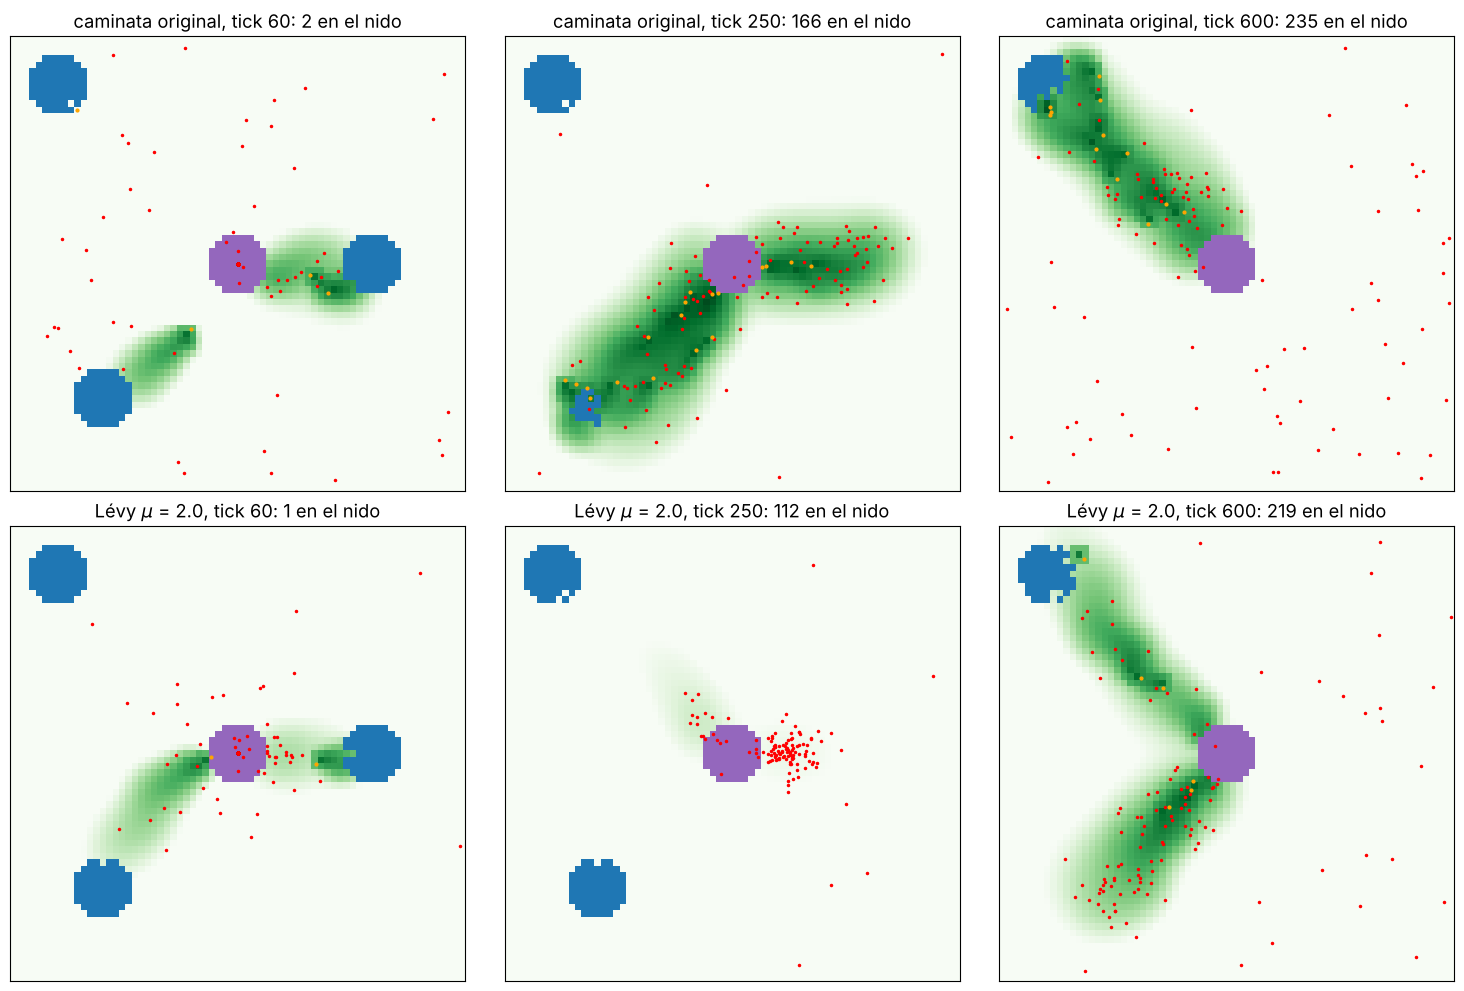

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for fila, (mov, mu) in enumerate([("caminata", None), ("levy", 2.0)]):
    h = Hormiguero(movimiento=mov, mu=mu or 2.0, rng=np.random.default_rng(7))
    for ax, t_obj in zip(axs[fila], [60, 250, 600]):
        while h.ticks < t_obj:
            h.paso()
        nombre = "caminata original" if mov == "caminata" else rf"Lévy $\mu$ = {mu}"
        dibujar_mundo(ax, h, f"{nombre}, tick {h.ticks}: {h.recolectada} en el nido")
plt.tight_layout()
plt.show()

## 5. Eficiencia: muchas simulaciones

Una simulación no basta: el modelo es aleatorio. Para cada estrategia corremos 30 simulaciones independientes y reportamos la **media** y la **desviación estándar** de tres medidas:

* $t_{\text{primera}}$: tick en que alguna hormiga encuentra comida por primera vez (eficiencia de la **búsqueda** pura).
* $t_{50}$ y $t_{90}$: ticks hasta llevar al nido el 50 % y el 90 % de la comida (eficiencia del **forrajeo** completo, que incluye el reclutamiento por feromona).

Comparamos la caminata original con vuelos de Lévy de $\mu = 1.5, 2, 2.5, 3$ en los tres escenarios de comida, en el mundo original de NetLogo (71 × 71 parcelas, 125 hormigas).

*(Esta celda tarda unos minutos.)*

In [8]:
ESTRATEGIAS = [("caminata", None), ("levy", 1.5), ("levy", 2.0), ("levy", 2.5), ("levy", 3.0)]
ETIQUETA = {("caminata", None): "caminata original",
            **{("levy", mu): f"Lévy μ={mu}" for mu in [1.5, 2.0, 2.5, 3.0]}}


def correr(movimiento, mu, escenario, t_max, semilla, **kw):
    """
    Corre una simulación y regresa (t_primera, t50, t90, serie de comida recolectada).
    Los tiempos que no se alcanzan antes de t_max se reportan como t_max.
    """
    h = Hormiguero(movimiento=movimiento, mu=mu or 2.0, escenario=escenario,
                   rng=np.random.default_rng(semilla), **kw)
    serie = np.zeros(t_max + 1)
    t50 = t90 = t_max
    for t in range(1, t_max + 1):
        h.paso()
        serie[t] = h.recolectada / h.comida_inicial
        if t50 == t_max and serie[t] >= 0.5:
            t50 = t
        if serie[t] >= 0.9:
            t90 = t
            serie[t:] = serie[t]          # a partir de aquí ya no lo necesitamos
            break
    t1 = h.primer_hallazgo if h.primer_hallazgo is not None else t_max
    return t1, t50, t90, serie


N_REP, T_MAX = 30, 1500
ESCENARIOS = ["original", "lejana", "dispersa"]
resultados = {}      # (escenario, estrategia) -> arreglo (N_REP, 3) con t1, t50, t90
series = {}          # (escenario, estrategia) -> arreglo (N_REP, T_MAX + 1)
for esc in ESCENARIOS:
    for est in ESTRATEGIAS:
        filas, ss = [], []
        for rep in range(N_REP):
            # La misma semilla para todas las estrategias: mismas posiciones de comida
            # en el escenario disperso (comparación pareada).
            t1, t50, t90, serie = correr(*est, esc, T_MAX, semilla=1000 * ESCENARIOS.index(esc) + rep)
            filas.append((t1, t50, t90))
            ss.append(serie)
        resultados[(esc, est)] = np.array(filas)
        series[(esc, est)] = np.array(ss)

for esc in ESCENARIOS:
    print(f"\nEscenario '{esc}'  (media ± desv. est. de {N_REP} simulaciones, en ticks)")
    print(f"{'estrategia':20s} {'t_primera':>14s} {'t_50':>14s} {'t_90':>14s}")
    for est in ESTRATEGIAS:
        R = resultados[(esc, est)]
        print(f"{ETIQUETA[est]:20s}" + "".join(f"{m:8.0f} ± {s:4.0f}" for m, s in zip(R.mean(0), R.std(0))))


Escenario 'original'  (media ± desv. est. de 30 simulaciones, en ticks)
estrategia                t_primera           t_50           t_90
caminata original         28 ±    8     359 ±  101     854 ±  201
Lévy μ=1.5                35 ±   10     384 ±   95     930 ±  209
Lévy μ=2.0                39 ±   13     436 ±  112    1162 ±  262
Lévy μ=2.5                52 ±   15     549 ±  158    1331 ±  218
Lévy μ=3.0                65 ±   20     606 ±  216    1496 ±   23

Escenario 'lejana'  (media ± desv. est. de 30 simulaciones, en ticks)
estrategia                t_primera           t_50           t_90
caminata original         77 ±   17     486 ±  159     609 ±  235
Lévy μ=1.5                72 ±   20     396 ±  143     526 ±  251
Lévy μ=2.0               102 ±   32     527 ±  205     790 ±  373
Lévy μ=2.5               136 ±   50     927 ±  349    1171 ±  396
Lévy μ=3.0               187 ±   61    1145 ±  392    1300 ±  368

Escenario 'dispersa'  (media ± desv. est. de 30 simulaciones, e

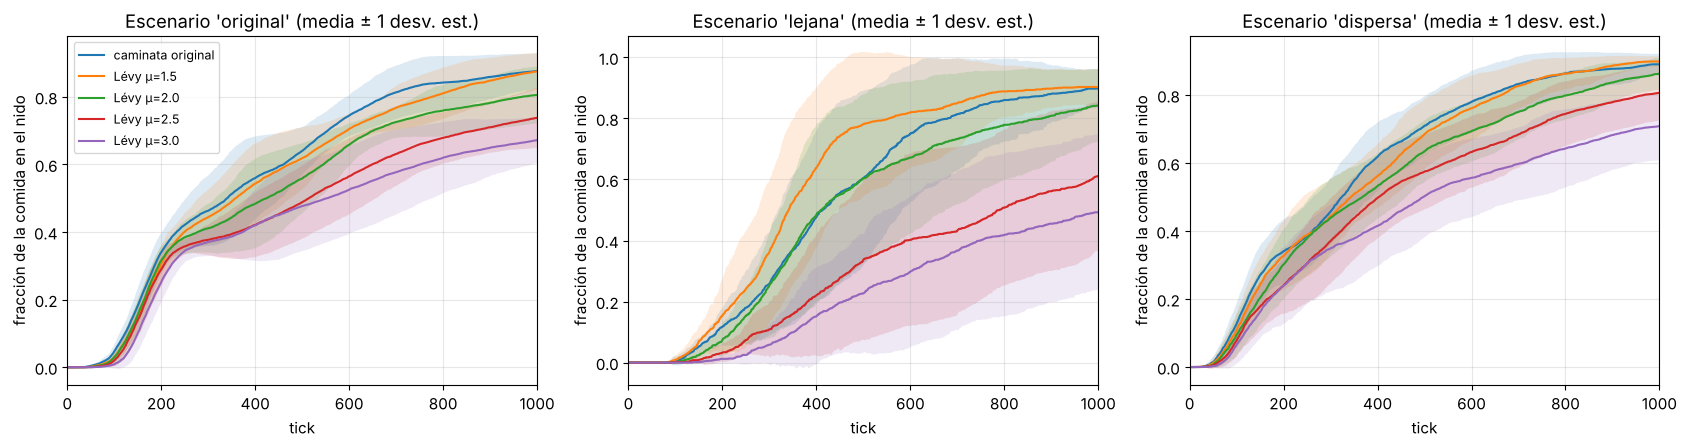

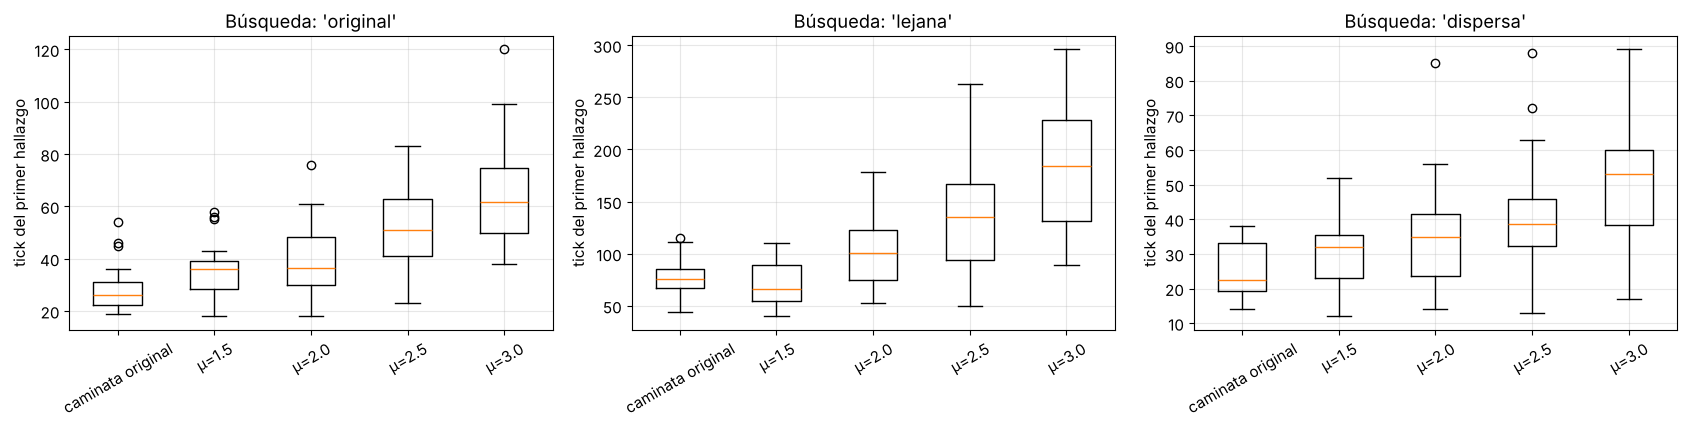

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
tt = np.arange(T_MAX + 1)
for ax, esc in zip(axs, ESCENARIOS):
    for est in ESTRATEGIAS:
        S = series[(esc, est)]
        m, s = S.mean(0), S.std(0)
        ax.plot(tt, m, label=ETIQUETA[est])
        ax.fill_between(tt, m - s, m + s, alpha=0.15)
    ax.set_xlim(0, 1000)
    ax.set_xlabel("tick")
    ax.set_ylabel("fracción de la comida en el nido")
    ax.set_title(f"Escenario '{esc}' (media ± 1 desv. est.)")
axs[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, esc in zip(axs, ESCENARIOS):
    datos = [resultados[(esc, est)][:, 0] for est in ESTRATEGIAS]
    ax.boxplot(datos, tick_labels=[ETIQUETA[e].replace("Lévy ", "") for e in ESTRATEGIAS])
    ax.set_ylabel("tick del primer hallazgo")
    ax.set_title(f"Búsqueda: '{esc}'")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [10]:
# ¿Son significativas las diferencias? Prueba de Mann-Whitney (no supone normalidad)
# de cada estrategia de Lévy contra la caminata original.
for esc in ESCENARIOS:
    base = resultados[(esc, ESTRATEGIAS[0])]
    print(f"\nEscenario '{esc}': valor p (Mann-Whitney, dos colas) contra la caminata original")
    for est in ESTRATEGIAS[1:]:
        R = resultados[(esc, est)]
        p1, p50, p90 = (stats.mannwhitneyu(R[:, k], base[:, k]).pvalue for k in range(3))
        print(f"   {ETIQUETA[est]:12s}: t_primera p = {p1:.3f}   t_50 p = {p50:.3f}   t_90 p = {p90:.3f}")


Escenario 'original': valor p (Mann-Whitney, dos colas) contra la caminata original
   Lévy μ=1.5  : t_primera p = 0.004   t_50 p = 0.222   t_90 p = 0.072
   Lévy μ=2.0  : t_primera p = 0.000   t_50 p = 0.003   t_90 p = 0.000
   Lévy μ=2.5  : t_primera p = 0.000   t_50 p = 0.000   t_90 p = 0.000
   Lévy μ=3.0  : t_primera p = 0.000   t_50 p = 0.000   t_90 p = 0.000

Escenario 'lejana': valor p (Mann-Whitney, dos colas) contra la caminata original
   Lévy μ=1.5  : t_primera p = 0.307   t_50 p = 0.031   t_90 p = 0.065
   Lévy μ=2.0  : t_primera p = 0.002   t_50 p = 0.584   t_90 p = 0.137
   Lévy μ=2.5  : t_primera p = 0.000   t_50 p = 0.000   t_90 p = 0.000
   Lévy μ=3.0  : t_primera p = 0.000   t_50 p = 0.000   t_90 p = 0.000

Escenario 'dispersa': valor p (Mann-Whitney, dos colas) contra la caminata original
   Lévy μ=1.5  : t_primera p = 0.110   t_50 p = 0.359   t_90 p = 0.520
   Lévy μ=2.0  : t_primera p = 0.005   t_50 p = 0.031   t_90 p = 0.000
   Lévy μ=2.5  : t_primera p = 0.000 

### Un mundo más grande y menos hormigas

En el mundo de NetLogo, 125 hormigas cubren muy rápido 71 × 71 parcelas: la comida es "abundante" en relación con el número de buscadores. Para acercarnos a la situación en la que se supone que los vuelos de Lévy ayudan (**recursos escasos** respecto al área que hay que explorar) repetimos la medición de la búsqueda en un mundo de 201 × 201 parcelas con solo 10 hormigas, y medimos únicamente el tiempo hasta el primer hallazgo.


Mundo grande, escenario 'lejana': tick del primer hallazgo (media ± desv. est.)
   caminata original       1207 ±   820
   Lévy μ=1.5               911 ±   662
                        (contra la caminata original: p = 0.337)
   Lévy μ=2.0              1099 ±   887
                        (contra la caminata original: p = 0.636)
   Lévy μ=2.5              2031 ±  1014   (2 sin éxito antes de 4000)
                        (contra la caminata original: p = 0.011)
   Lévy μ=3.0              3193 ±  1037   (10 sin éxito antes de 4000)
                        (contra la caminata original: p = 0.000)

Mundo grande, escenario 'dispersa': tick del primer hallazgo (media ± desv. est.)
   caminata original        122 ±    91
   Lévy μ=1.5               143 ±   107
                        (contra la caminata original: p = 0.685)
   Lévy μ=2.0               258 ±   292
                        (contra la caminata original: p = 0.189)
   Lévy μ=2.5               299 ±   403
                        (

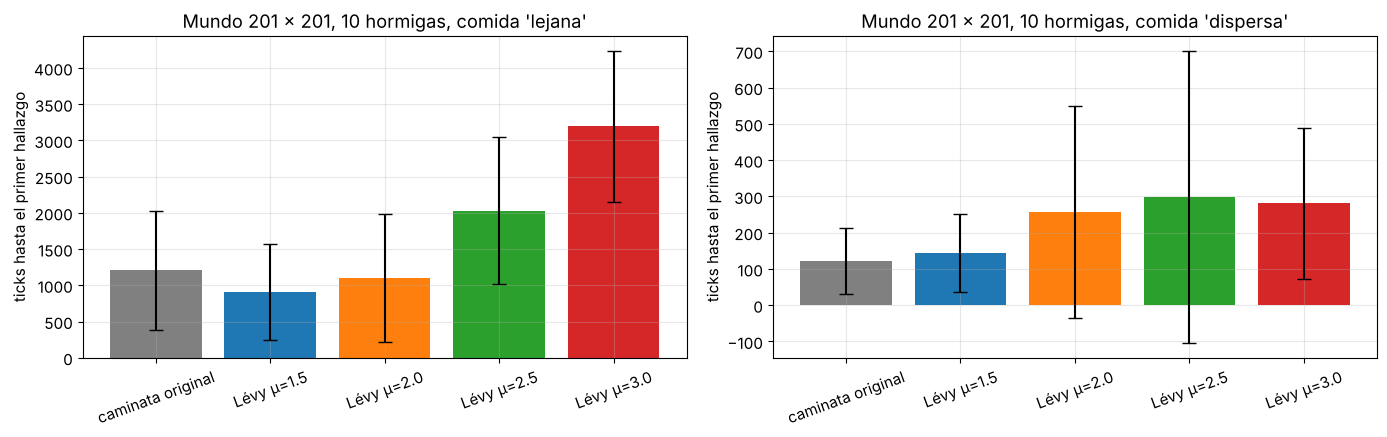

In [11]:
N_REP_G, T_MAX_G = 20, 4000
res_grande = {}
for esc in ["lejana", "dispersa"]:
    for est in ESTRATEGIAS:
        t1s = []
        for rep in range(N_REP_G):
            h = Hormiguero(movimiento=est[0], mu=est[1] or 2.0, escenario=esc, poblacion=10,
                           max_p=100, paso_maximo=200, rng=np.random.default_rng(5000 + rep))
            while h.primer_hallazgo is None and h.ticks < T_MAX_G:
                h.paso()
            t1s.append(h.primer_hallazgo if h.primer_hallazgo is not None else T_MAX_G)
        res_grande[(esc, est)] = np.array(t1s)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, esc in zip(axs, ["lejana", "dispersa"]):
    print(f"\nMundo grande, escenario '{esc}': tick del primer hallazgo (media ± desv. est.)")
    medias, desv = [], []
    for est in ESTRATEGIAS:
        r = res_grande[(esc, est)]
        sin_exito = np.sum(r >= T_MAX_G)
        print(f"   {ETIQUETA[est]:20s} {r.mean():7.0f} ± {r.std():5.0f}"
              + (f"   ({sin_exito} sin éxito antes de {T_MAX_G})" if sin_exito else ""))
        if est != ESTRATEGIAS[0]:
            p = stats.mannwhitneyu(r, res_grande[(esc, ESTRATEGIAS[0])]).pvalue
            print(f"   {'':20s} (contra la caminata original: p = {p:.3f})")
        medias.append(r.mean())
        desv.append(r.std())
    ax.bar(range(len(ESTRATEGIAS)), medias, yerr=desv, capsize=5,
           color=["gray"] + [f"C{k}" for k in range(4)])
    ax.set_xticks(range(len(ESTRATEGIAS)), [ETIQUETA[e] for e in ESTRATEGIAS], rotation=20)
    ax.set_ylabel("ticks hasta el primer hallazgo")
    ax.set_title(f"Mundo 201 × 201, 10 hormigas, comida '{esc}'")
plt.tight_layout()
plt.show()

## 6. Verificación con NetLogo

Todo lo anterior usa la reimplementación en Python. ¿Coincide con el modelo de NetLogo modificado? Corrimos `Ants-Levy.nlogo` en NetLogo 6.4.0 (sin interfaz gráfica, con `netlogo-headless.sh`) con el experimento de BehaviorSpace incluido en el archivo, `levy-vs-caminata`: 30 repeticiones de cada combinación de movimiento, $\mu$ y escenario, 720 simulaciones en total. Como la caminata original no usa $\mu$, tiene 120 repeticiones. Los resultados están en [`_data/netlogo_levy-vs-caminata.csv`](https://github.com/uncrayon/biologia-matematica/blob/main/_data/netlogo_levy-vs-caminata.csv); BehaviorSpace reporta −1 cuando un tiempo no se alcanzó y lo reemplazamos por el límite de 1 500 ticks, igual que en Python.

In [12]:
import pathlib
import pandas as pd

RUTA = pathlib.Path("../_data/netlogo_levy-vs-caminata.csv")
URL = ("https://raw.githubusercontent.com/uncrayon/biologia-matematica/main/"
       "_data/netlogo_levy-vs-caminata.csv")
nl = pd.read_csv(RUTA if RUTA.exists() else URL)
for col in ["primer-hallazgo", "tick-50", "tick-90"]:
    nl[col] = nl[col].where(nl[col] >= 0, T_MAX)          # -1 = no se alcanzó
nl["estrategia"] = np.where(nl["movimiento"] == "caminata-aleatoria", "caminata original",
                            "Lévy μ=" + nl["mu"].astype(float).astype(str))

cols = ["primer-hallazgo", "tick-50", "tick-90"]
for esc in ESCENARIOS:
    print(f"\nEscenario '{esc}': media ± desv. est. (NetLogo | Python)")
    print(f"{'estrategia':20s} {'t_primera':>24s} {'t_50':>24s} {'t_90':>24s}")
    for est in ESTRATEGIAS:
        sel = nl[(nl["escenario-comida"] == esc) & (nl["estrategia"] == ETIQUETA[est])]
        R = resultados[(esc, est)]
        celdas = [f"{sel[c].mean():5.0f}±{sel[c].std():4.0f} | {R[:, k].mean():5.0f}±{R[:, k].std():4.0f}"
                  for k, c in enumerate(cols)]
        print(f"{ETIQUETA[est]:20s} " + " ".join(f"{x:>24s}" for x in celdas))

# La única ventaja de Lévy que encontramos en Python: mu = 1.5, escenario 'lejana', t_50.
lej = nl[nl["escenario-comida"] == "lejana"]
a = lej[lej["estrategia"] == "Lévy μ=1.5"]["tick-50"]
b_ = lej[lej["estrategia"] == "caminata original"]["tick-50"]
print(f"\nNetLogo, 'lejana', t_50: Lévy μ=1.5 = {a.mean():.0f}, caminata = {b_.mean():.0f},"
      f" Mann-Whitney p = {stats.mannwhitneyu(a, b_).pvalue:.2f}")


Escenario 'original': media ± desv. est. (NetLogo | Python)
estrategia                          t_primera                     t_50                     t_90
caminata original        30±   7 |    28±   8    346±  87 |   359± 101    882± 222 |   854± 201
Lévy μ=1.5               33±   8 |    35±  10    387±  98 |   384±  95    910± 167 |   930± 209
Lévy μ=2.0               40±  10 |    39±  13    444± 111 |   436± 112   1096± 287 |  1162± 262
Lévy μ=2.5               51±  15 |    52±  15    551± 128 |   549± 158   1405± 201 |  1331± 218
Lévy μ=3.0               63±  18 |    65±  20    561± 169 |   606± 216   1499±   4 |  1496±  23

Escenario 'lejana': media ± desv. est. (NetLogo | Python)
estrategia                          t_primera                     t_50                     t_90
caminata original        74±  21 |    77±  17    391± 143 |   486± 159    537± 247 |   609± 235
Lévy μ=1.5               70±  17 |    72±  20    408± 121 |   396± 143    517± 182 |   526± 251
Lévy μ=2.0      

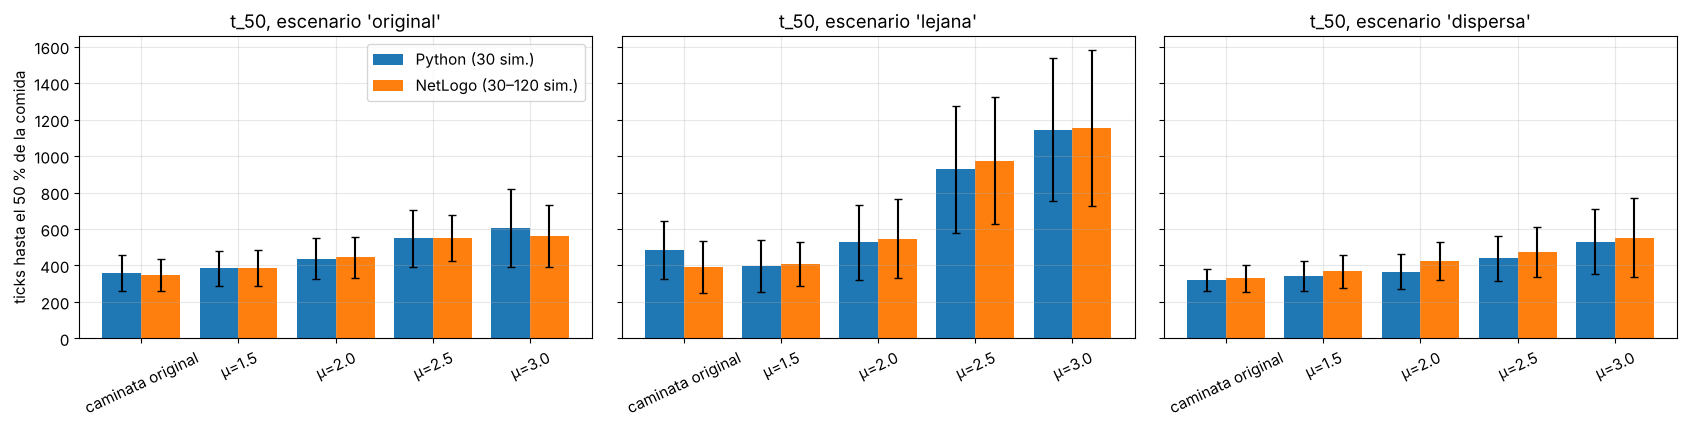

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
x = np.arange(len(ESTRATEGIAS))
for ax, esc in zip(axs, ESCENARIOS):
    py = [resultados[(esc, est)][:, 1].mean() for est in ESTRATEGIAS]
    py_s = [resultados[(esc, est)][:, 1].std() for est in ESTRATEGIAS]
    g = nl[nl["escenario-comida"] == esc].groupby("estrategia")["tick-50"]
    nlm = [g.mean()[ETIQUETA[e]] for e in ESTRATEGIAS]
    nls = [g.std()[ETIQUETA[e]] for e in ESTRATEGIAS]
    ax.bar(x - 0.2, py, 0.4, yerr=py_s, capsize=3, label="Python (30 sim.)")
    ax.bar(x + 0.2, nlm, 0.4, yerr=nls, capsize=3, label="NetLogo (30–120 sim.)")
    ax.set_xticks(x, [ETIQUETA[e].replace("Lévy ", "") for e in ESTRATEGIAS], rotation=25)
    ax.set_title(f"t_50, escenario '{esc}'")
axs[0].set_ylabel("ticks hasta el 50 % de la comida")
axs[0].legend()
plt.tight_layout()
plt.show()

**Lectura.** Las dos implementaciones coinciden muy bien en casi todo: los tiempos y su variabilidad son del mismo tamaño, y el orden de las estrategias es el mismo (cuanto mayor $\mu$, más lenta la colonia). La diferencia más notable está en la caminata original del escenario `lejana`: en NetLogo junta el 50 % de la comida más rápido (unos 390 ticks contra unos 490 en Python). La explicación más probable es la simplificación que hicimos en Python: allí todas las hormigas deciden con el estado al inicio del tick, mientras que en NetLogo actúan una tras otra y pueden oler la feromona que otra acaba de dejar, así que el reclutamiento hacia una fuente lejana es algo más eficiente. Con eso desaparece la pequeña ventaja de $\mu = 1.5$ que habíamos encontrado en ese escenario: en NetLogo los vuelos de Lévy no superan a la caminata original en ningún escenario.

## 7. ¿En qué condiciones ganan los vuelos de Lévy?

Lo que muestran las simulaciones en Python y en NetLogo (los valores exactos están en las tablas de arriba):

1. **En el mundo original de NetLogo, ningún vuelo de Lévy supera de forma significativa a la caminata original.** Con $\mu = 1.5$ los resultados son parecidos (incluso un poco peores en el primer hallazgo del escenario original). Con $\mu = 2$, $2.5$ y $3$ las hormigas son claramente más lentas en los tres escenarios, y cuanto mayor es $\mu$, peor les va.
2. **La razón es contra qué estamos comparando.** La caminata original no es browniana: es una caminata correlacionada con una longitud de persistencia de unos 50 pasos, comparable al tamaño del mundo. Ya tiene la ventaja que se le atribuye a los vuelos de Lévy: no regresa sobre sus pasos. Un vuelo de Lévy con $\mu = 3$, en cambio, consiste casi siempre en pasos de 1 o 2 parcelas con una dirección completamente nueva; es lo más parecido a una caminata **browniana** y resulta la peor estrategia en todos los escenarios. Si comparamos Lévy contra el movimiento casi browniano ($\mu = 1.5$ o $2$ contra $\mu = 3$), sí se reproduce la predicción teórica: los vuelos de Lévy encuentran la comida mucho antes.
3. **La única pista de ventaja para Lévy aparece con comida escasa y lejana, y con $\mu$ pequeño, y es muy débil.** En Python, en el escenario `lejana`, con $\mu = 1.5$ las hormigas llevaban el 50 % de la comida al nido antes que con la caminata original (unos 400 contra 490 ticks, $p \approx 0.03$), pero esa diferencia **no se reproduce en NetLogo** (unos 410 contra 390 ticks), donde la caminata original recluta mejor. En el mundo grande con una sola fuente lejana (solo en Python), $\mu = 1.5$ encuentra la comida antes en promedio (unos 900 contra 1 200 ticks), pero sin significancia estadística ($p \approx 0.34$). Con fuentes diminutas dispersas, la caminata original es igual o mejor.
4. **Con comida abundante y cercana, manda la feromona.** Las primeras fuentes se encuentran rápido con cualquier estrategia; lo que determina el forrajeo es el reclutamiento por rastros, que es igual para todas. Las diferencias aparecen cuando una fuente se agota y las hormigas tienen que buscar la siguiente.
5. **Las paredes** cortan los vuelos largos: en un mundo cerrado y pequeño, la ventaja potencial de los pasos largos se pierde.

**Respuesta.** Los vuelos de Lévy superan a una búsqueda **sin memoria de dirección** (browniana) cuando los recursos son escasos, dispersos y lejanos, el espacio es grande comparado con el número de buscadores y no hay pistas (feromona) que guíen la búsqueda. Contra la caminata del modelo de NetLogo, que ya es muy persistente, **no encontramos una ventaja robusta**: lo más cercano es $\mu$ pequeño (movimiento casi balístico) con comida escasa y lejana, una tendencia que no sobrevive al pasar de Python a NetLogo. Que lo mejor sea moverse casi en línea recta concuerda con la teoría para recursos que se encuentran una sola vez. La moraleja va más allá de las hormigas: "los vuelos de Lévy son más eficientes" siempre significa "más eficientes **que cierta alternativa, en cierto entorno**". Los estudios de campo enfrentan exactamente este problema al decidir si un animal "hace" vuelos de Lévy.

**Referencias:** Wilensky, U. (1997). NetLogo Ants model. Viswanathan, G. M. et al. (1999). Optimizing the success of random searches. *Nature* 401: 911–914. Edwards, A. M. et al. (2007). Revisiting Lévy flight search patterns of wandering albatrosses, bumblebees and deer. *Nature* 449: 1044–1048. Sims, D. W. et al. (2008). *Nature* 451: 1098–1102. Humphries, N. E. et al. (2010). *Nature* 465: 1066–1069. Harris, T. H. et al. (2012). *Nature* 486: 545–548.